In [1]:
import pandas as pd
df = pd.read_csv('startup_funding.csv')
df.head()

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN


In [2]:
df.columns = ['sno','date','startup','vertical','subvertical','city','investors','inv_type','amount','remarks']

print(df.shape)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df.info()

(3044, 10)
sno               0
date              0
startup           0
vertical        171
subvertical     936
city            180
investors        24
inv_type          4
amount          960
remarks        2625
dtype: int64
Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   sno          3044 non-null   int64 
 1   date         3044 non-null   object
 2   startup      3044 non-null   object
 3   vertical     2873 non-null   object
 4   subvertical  2108 non-null   object
 5   city         2864 non-null   object
 6   investors    3020 non-null   object
 7   inv_type     3040 non-null   object
 8   amount       2084 non-null   object
 9   remarks      419 non-null    object
dtypes: int64(1), object(9)
memory usage: 237.9+ KB


In [3]:
# drop columns we don't need
df = df.drop(columns=['sno', 'remarks'])

# amount: remove commas and convert to number
df['amount'] = df['amount'].astype(str).str.replace(',', '', regex=True)
df['amount'] = pd.to_numeric(df['amount'], errors='coerce')

# date: convert to real dates and extract the year
df['date'] = pd.to_datetime(df['date'], dayfirst=True, errors='coerce')
df['year'] = df['date'].dt.year

print(df['amount'].isnull().sum())
print(df['date'].isnull().sum())
print(df['year'].value_counts().sort_index())
df.head()

979
8
year
2015.0    929
2016.0    993
2017.0    687
2018.0    309
2019.0    111
2020.0      7
Name: count, dtype: int64


,date,startup,vertical,subvertical,city,investors,inv_type,amount,year
0,2020-01-09,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,200000000.0,2020.0
1,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,8048394.0,2020.0
2,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,18358860.0,2020.0
3,2020-01-02,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,3000000.0,2020.0
4,2020-01-02,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,1800000.0,2020.0


In [4]:
print(df['city'].nunique())
print(df['city'].value_counts().head(25))

112
city
Bangalore              700
Mumbai                 567
New Delhi              421
Gurgaon                287
Bengaluru              141
Pune                   105
Hyderabad               99
Chennai                 97
Noida                   92
Gurugram                50
Ahmedabad               38
Delhi                   34
Jaipur                  30
Kolkata                 21
Indore                  13
Chandigarh              11
Vadodara                10
Goa                     10
Singapore                8
Coimbatore               5
Pune / US                4
\\xc2\\xa0Gurgaon        4
Kanpur                   4
Nagpur                   3
\\xc2\\xa0New Delhi      3
Name: count, dtype: int64


In [5]:
# remove junk characters (covers both the literal text and the real hidden space)
df['city'] = df['city'].str.replace(r'(\\+x[0-9a-fA-F]{2})+', '', regex=True)
df['city'] = df['city'].str.replace('\xa0', ' ')

# keep only the part before "/" (so "Pune / US" becomes "Pune"), then trim spaces
df['city'] = df['city'].str.split('/').str[0].str.strip()

# merge same-city names
df['city'] = df['city'].replace({
    'Bengaluru': 'Bangalore',
    'Gurugram': 'Gurgaon',
    'Delhi': 'New Delhi'
})

print(df['city'].nunique())
print(df['city'].value_counts().head(15))

77
city
Bangalore     849
Mumbai        573
New Delhi     462
Gurgaon       342
Pune          112
Hyderabad     100
Chennai        98
Noida          94
Ahmedabad      38
Jaipur         30
Kolkata        21
Indore         13
Chandigarh     11
Goa            11
Vadodara       10
Name: count, dtype: int64


In [6]:
# remove hidden junk characters, same trick as city
df['vertical'] = df['vertical'].str.replace(r'(\\+x[0-9a-fA-F]{2})+', '', regex=True)
df['vertical'] = df['vertical'].str.replace('\xa0', ' ').str.strip()

print(df['vertical'].nunique())
print(df['vertical'].value_counts().head(30))

821
vertical
Consumer Internet            941
Technology                   478
eCommerce                    186
Healthcare                    70
Finance                       62
ECommerce                     61
Logistics                     32
E-Commerce                    29
Education                     24
Food & Beverage               23
Ed-Tech                       14
E-commerce                    12
FinTech                        9
IT                             8
Ecommerce                      8
Others                         6
Real Estate                    6
Food and Beverage              6
Fin-Tech                       6
Online Food Delivery           5
Health and Wellness            5
Logistics Tech                 5
Online Education Platform      5
Transport                      4
Transportation                 4
Food                           3
Services                       3
Automobile                     3
EdTech                         3
Social Media                  

In [7]:
# make a comparison key: lowercase, no hyphens, no spaces
key = df['vertical'].str.lower().str.replace('-', '', regex=False).str.replace(' ', '', regex=False)

# map each cleaned key to one standard name
std = {
    'ecommerce': 'E-Commerce',
    'edtech': 'EdTech',
    'education': 'EdTech',
    'onlineeducationplatform': 'EdTech',
    'fintech': 'FinTech',
    'foodandbeverage': 'Food & Beverage',
    'food&beverage': 'Food & Beverage',
    'transport': 'Transportation',
    'transportation': 'Transportation',
    'logisticstech': 'Logistics',
    'it': 'Technology',
}

df['vertical'] = key.map(std).fillna(df['vertical'])

print(df['vertical'].nunique())
print(df['vertical'].value_counts().head(15))

805
vertical
Consumer Internet         941
Technology                486
E-Commerce                299
Healthcare                 70
Finance                    62
EdTech                     49
Logistics                  37
Food & Beverage            29
FinTech                    16
Transportation              8
Others                      6
Real Estate                 6
Online Food Delivery        5
Health and Wellness         5
Information Technology      3
Name: count, dtype: int64


Rows removed: 0 | Rows left: 3044
        deals  disclosed     total_usd  total_usd_bn
year                                                
2015.0    929        642  8.597207e+09          8.60
2016.0    993        586  3.828089e+09          3.83
2017.0    687        456  1.042931e+10         10.43
2018.0    309        264  5.116118e+09          5.12
2019.0    111        104  9.686577e+09          9.69


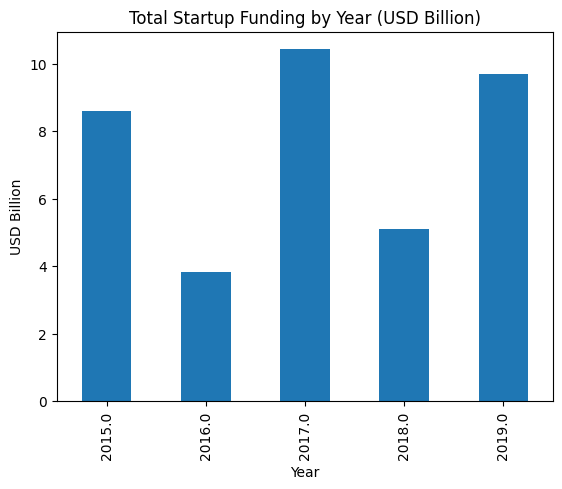

In [8]:
import matplotlib.pyplot as plt

# remove duplicates (now that sno is gone)
before = len(df)
df = df.drop_duplicates()
print("Rows removed:", before - len(df), "| Rows left:", len(df))

# yearly summary (excluding 2020, only 7 rows)
yearly = df[df['year'] < 2020].groupby('year').agg(
    deals=('startup', 'count'),
    disclosed=('amount', 'count'),
    total_usd=('amount', 'sum')
)
yearly['total_usd_bn'] = (yearly['total_usd'] / 1e9).round(2)
print(yearly)

yearly['total_usd_bn'].plot(kind='bar', title='Total Startup Funding by Year (USD Billion)')
plt.ylabel('USD Billion')
plt.xlabel('Year')
plt.show()

In [9]:
# 10 biggest deals overall
top = df.nlargest(10, 'amount')[['date','startup','vertical','amount']].copy()
top['amount_mn'] = (top['amount'] / 1e6).round(0)
print(top[['date','startup','vertical','amount_mn']])

# average vs median deal size by year (2015-2019, disclosed deals only)
size = df[(df['year'] < 2020) & df['amount'].notna()].groupby('year')['amount'].agg(['mean', 'median'])
print((size / 1e6).round(2))

           date           startup                            vertical  \
60   2019-08-27  Rapido Bike Taxi                      Transportation   
651  2017-08-11          Flipkart                          E-Commerce   
830  2017-05-18             Paytm                          E-Commerce   
966  2017-03-21          Flipkart                          E-Commerce   
31   2019-11-25             Paytm                             FinTech   
2648 2015-07-28      Flipkart.com                  Online Marketplace   
2459 2015-09-29             Paytm    E-Commerce & M-Commerce platform   
188  2018-08-30        True North                             Finance   
33   2019-10-02             Udaan                                 B2B   
2244 2015-11-18               Ola  Car Aggregator & Retail Mobile App   

      amount_mn  
60       3900.0  
651      2500.0  
830      1400.0  
966      1400.0  
31       1000.0  
2648      700.0  
2459      680.0  
188       600.0  
33        585.0  
2244      500.0 

In [10]:
import numpy as np

# flag the suspicious row, then blank its amount
df.loc[(df['startup'] == 'Rapido Bike Taxi') & (df['amount'] > 1e9), 'amount'] = np.nan

# recompute yearly summary
yearly = df[df['year'] < 2020].groupby('year').agg(
    deals=('startup', 'count'),
    disclosed=('amount', 'count'),
    total_usd=('amount', 'sum')
)
yearly['total_usd_bn'] = (yearly['total_usd'] / 1e9).round(2)
print(yearly)

        deals  disclosed     total_usd  total_usd_bn
year                                                
2015.0    929        642  8.597207e+09          8.60
2016.0    993        586  3.828089e+09          3.83
2017.0    687        456  1.042931e+10         10.43
2018.0    309        264  5.116118e+09          5.12
2019.0    111        103  5.786577e+09          5.79


In [11]:
# top 10 sectors by total funding
sector = df.groupby('vertical').agg(
    deals=('startup', 'count'),
    total_usd=('amount', 'sum')
)
sector['total_usd_bn'] = (sector['total_usd'] / 1e9).round(2)
print(sector.sort_values('total_usd', ascending=False).head(10)[['deals', 'total_usd_bn']])

# top 10 cities by total funding, plus share of the total
city = df.groupby('city')['amount'].sum().sort_values(ascending=False)
share = (city / city.sum() * 100).round(1)
print(share.head(10))
print("Top 3 cities share:", share.head(3).sum().round(1), "%")

                                    deals  total_usd_bn
vertical                                               
E-Commerce                            299          8.25
Consumer Internet                     941          6.25
Technology                            486          2.26
Finance                                62          1.97
FinTech                                16          1.36
Online Marketplace                      2          0.70
E-Commerce & M-Commerce platform        1          0.68
B2B                                     2          0.59
EdTech                                 49          0.51
Car Aggregator & Retail Mobile App      1          0.50
city
Bangalore     44.4
Mumbai        15.0
Gurgaon       11.8
New Delhi     10.2
Noida          3.8
Chennai        2.2
Pune           2.2
Menlo Park     1.4
Hyderabad      1.2
India          1.1
Name: amount, dtype: float64
Top 3 cities share: 71.2 %


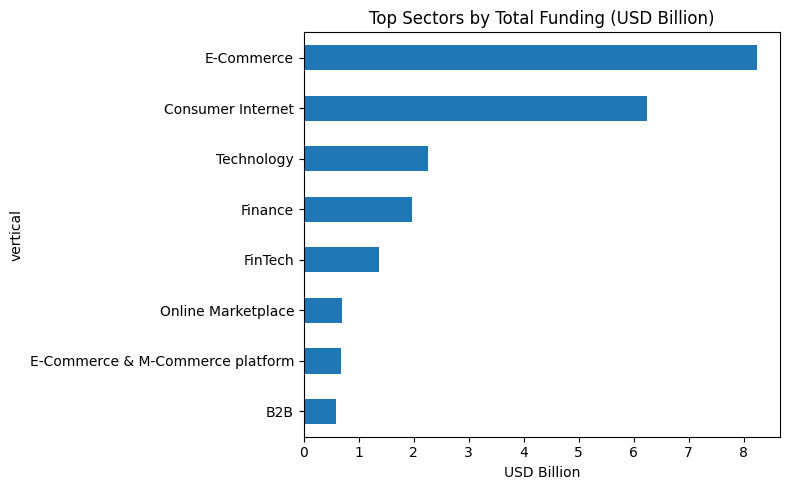

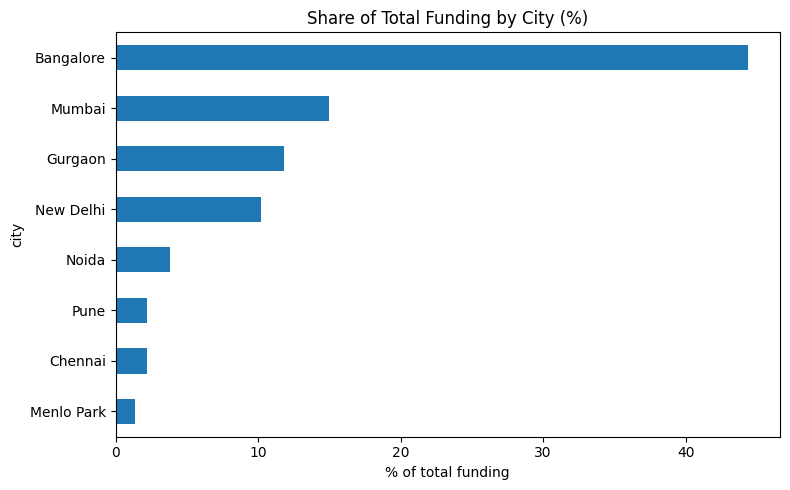

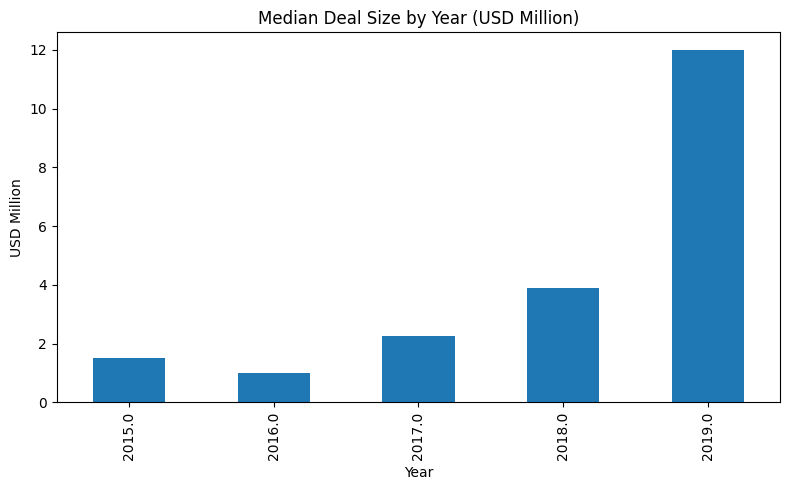

In [12]:
import matplotlib.pyplot as plt

# Chart 1: top 8 sectors by funding
s = sector.sort_values('total_usd', ascending=False).head(8)['total_usd_bn']
s.sort_values().plot(kind='barh', figsize=(8,5), title='Top Sectors by Total Funding (USD Billion)')
plt.xlabel('USD Billion')
plt.tight_layout()
plt.savefig('chart_sectors.png', dpi=150)
plt.show()

# Chart 2: top 8 cities by share of funding
share.head(8).sort_values().plot(kind='barh', figsize=(8,5), title='Share of Total Funding by City (%)')
plt.xlabel('% of total funding')
plt.tight_layout()
plt.savefig('chart_cities.png', dpi=150)
plt.show()

# Chart 3: median deal size by year
med = df[(df['year'] < 2020) & df['amount'].notna()].groupby('year')['amount'].median() / 1e6
med.plot(kind='bar', figsize=(8,5), title='Median Deal Size by Year (USD Million)')
plt.ylabel('USD Million')
plt.xlabel('Year')
plt.tight_layout()
plt.savefig('chart_median.png', dpi=150)
plt.show()

In [13]:
import sqlite3
conn = sqlite3.connect('startup.db')
df.to_sql('funding', conn, index=False, if_exists='replace')

q1 = """
SELECT CAST(year AS INTEGER) AS year,
       COUNT(*) AS deals,
       COUNT(amount) AS disclosed,
       ROUND(SUM(amount)/1e9, 2) AS total_usd_bn
FROM funding
WHERE year < 2020
GROUP BY year
ORDER BY year;
"""

q2 = """
SELECT city,
       COUNT(*) AS deals,
       ROUND(SUM(amount)/1e9, 2) AS total_usd_bn
FROM funding
WHERE city IS NOT NULL
GROUP BY city
ORDER BY SUM(amount) DESC
LIMIT 10;
"""

q3 = """
SELECT vertical,
       COUNT(amount) AS disclosed_deals,
       ROUND(AVG(amount)/1e6, 2) AS avg_deal_usd_mn
FROM funding
WHERE amount IS NOT NULL
GROUP BY vertical
HAVING COUNT(amount) >= 20
ORDER BY avg_deal_usd_mn DESC;
"""

for q in (q1, q2, q3):
    print(pd.read_sql(q, conn))
    print()

# save the queries to a file for GitHub
with open('queries.sql', 'w') as f:
    f.write("-- Yearly funding\n" + q1 + "\n-- Top cities\n" + q2 + "\n-- Average deal size by sector (min 20 disclosed deals)\n" + q3)

   year  deals  disclosed  total_usd_bn
0  2015    929        642          8.60
1  2016    993        586          3.83
2  2017    687        456         10.43
3  2018    309        264          5.12
4  2019    111        103          5.79

         city  deals  total_usd_bn
0   Bangalore    849         14.60
1      Mumbai    573          4.94
2     Gurgaon    342          3.87
3   New Delhi    462          3.36
4       Noida     94          1.26
5     Chennai     98          0.72
6        Pune    112          0.72
7  Menlo Park      1          0.45
8   Hyderabad    100          0.40
9       India      5          0.35

            vertical  disclosed_deals  avg_deal_usd_mn
0         E-Commerce              204            40.42
1            Finance               57            34.59
2             EdTech               40            12.79
3  Consumer Internet              589            10.62
4          Logistics               27            10.20
5               None              131      

In [14]:
inv = df['investors'].dropna().str.replace(r'(\\+x[0-9a-fA-F]{2})+', '', regex=True)
inv = inv.str.replace('\xa0', ' ').str.split(',').explode().str.strip()
inv = inv[inv != '']

# merge a few common spelling variants (we'll check below)
inv = inv.str.replace('Undisclosed Investors', 'Undisclosed', regex=False)

print(inv.nunique())
print(inv.value_counts().head(15))

3250
investors
Sequoia Capital           72
Accel Partners            69
Kalaari Capital           50
Undisclosed               50
SAIF Partners             48
Blume Ventures            47
Indian Angel Network      42
Undisclosed investors     31
Ratan Tata                31
Nexus Venture Partners    30
Rajan Anandan             29
IDG Ventures              28
Tiger Global              28
Matrix Partners           24
Kae Capital               24
Name: count, dtype: int64


In [15]:
# 1. drop placeholder "investors"
inv = inv[~inv.str.lower().str.startswith('undisclosed')]

# 2. see which names might be variants of the big firms
for name in ['sequoia', 'accel', 'tiger', 'kalaari', 'saif', 'nexus']:
    print(inv[inv.str.lower().str.contains(name)].value_counts())
    print()

investors
Sequoia Capital                              72
Sequoia India                                22
Sequoia Capital India                        16
Sequoia                                       2
Sequoia Capital India Advisors                2
Sequoia Capital and Temasek Holdings          1
Xiaomi and Sequoia Capital India              1
Sequoia Capital & Matrix Partners             1
Saama Capital and Sequoia Capital             1
Sequoia and Jerry Yang                        1
Sequoia and Kalaari Capital.                  1
Sequoia Capital Global Equities               1
Sequoia Capital.                              1
Sequoia Capital India and Omidyar Network     1
Name: count, dtype: int64

investors
Accel Partners                                                      69
GHV Accelerator                                                      4
Accel Partners India                                                 4
Accel                                                               

investors
Sequoia Capital            121
Accel Partners              78
SAIF Partners               56
Kalaari Capital             55
Tiger Global Management     53
Blume Ventures              48
Indian Angel Network        42
Nexus Venture Partners      34
Ratan Tata                  31
Rajan Anandan               29
Name: count, dtype: int64


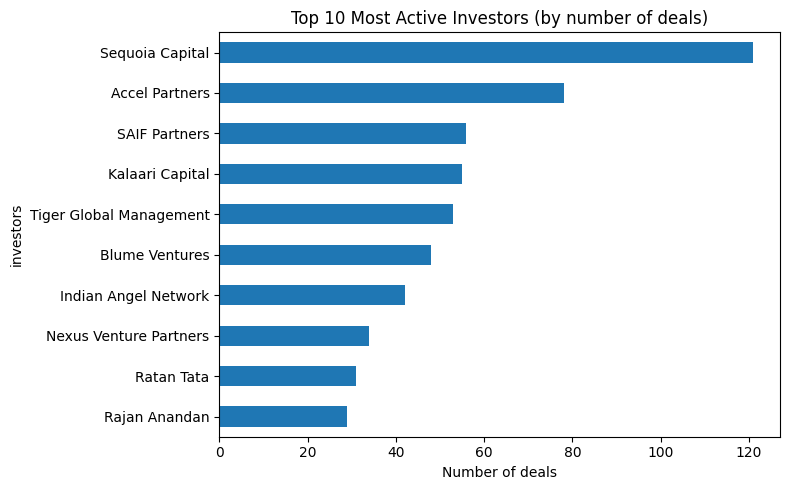

In [16]:
import re

def standardize(name):
    n = name.lower().strip().rstrip('.')
    # exclude accelerators/incubators so they don't match Accel
    if 'accelerator' in n or 'acceleration' in n:
        return name.strip().rstrip('.')
    if n.startswith('sequoia'):
        return 'Sequoia Capital'
    if re.match(r'^accel( partners?| india| us)?$', n):
        return 'Accel Partners'
    if n.startswith('tiger global'):
        return 'Tiger Global Management'
    if n.startswith('kalaari capital') and 'accelerator' not in n:
        return 'Kalaari Capital'
    if n.startswith('saif partners'):
        return 'SAIF Partners'
    if n.startswith('nexus venture'):
        return 'Nexus Venture Partners'
    return name.strip().rstrip('.')

inv2 = inv.apply(standardize)

# note: rows like "X and Y" are still counted under the full text
# (e.g. "Accel Partners and IDG Ventures"), a known limitation
top10 = inv2.value_counts().head(10)
print(top10)

top10.sort_values().plot(kind='barh', figsize=(8,5), title='Top 10 Most Active Investors (by number of deals)')
plt.xlabel('Number of deals')
plt.tight_layout()
plt.savefig('chart_investors.png', dpi=150)
plt.show()

In [17]:
med = df[(df['year'] < 2020) & df['amount'].notna()].groupby('year')['amount'].median() / 1e6
print(med.round(2))
print("Share of deals with missing amount:", round(df['amount'].isnull().mean() * 100, 1), "%")

year
2015.0     1.50
2016.0     1.00
2017.0     2.25
2018.0     3.90
2019.0    12.00
Name: amount, dtype: float64
Share of deals with missing amount: 32.2 %
